# Breast Cancer Tumor Classification

I compared several machine learning models on the Breast Cancer Wisconsin dataset (569 tumor samples, 30 measurements of cell nuclei) to see which one best tells malignant tumors from benign ones. I'm interested in biomedical research, so I wanted to see how machine learning works on real medical data and where it goes wrong.

I started from a short tutorial notebook that trained a random forest. I extended it with cross-validation, a model comparison, error analysis, a cutoff experiment, a feature experiment, a learning curve, and model explanations.

*This is an educational project, not a diagnostic tool!!*

## Setup
Settings and helper functions. I fixed the random seed (42) so the results can be reproduced.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_validate, RepeatedStratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (make_scorer, recall_score, precision_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'axes.titlesize': 13, 'axes.titleweight': 'bold', 'figure.dpi': 120})

# ---- settings ----
SEED = 42
TEST_SIZE = 0.2
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

# malignant = class 0, so recall/precision are scored on class 0
SCORING = {
    'accuracy': 'accuracy',
    'malignant_recall': make_scorer(recall_score, pos_label=0),
    'malignant_precision': make_scorer(precision_score, pos_label=0, zero_division=0),
    'roc_auc': 'roc_auc',
}


def load_data():
    """Breast Cancer Wisconsin dataset (569 samples, 30 features)."""
    data = load_breast_cancer(as_frame=True)
    return data.data, data.target, list(data.target_names)


def build_models():
    return {
        'Baseline (always benign)': DummyClassifier(strategy='most_frequent'),
        'Decision tree': DecisionTreeClassifier(random_state=SEED),
        'Random forest': RandomForestClassifier(n_estimators=300, random_state=SEED),
        'Gradient boosting': GradientBoostingClassifier(random_state=SEED),
        'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    }


def compare_models(models, X, y):
    """Repeated 5-fold cross-validation (15 fits per model)."""
    rows = []
    for name, model in models.items():
        r = cross_validate(model, X, y, cv=CV, scoring=SCORING, n_jobs=-1)
        rows.append({
            'model': name,
            'accuracy %': round(100 * r['test_accuracy'].mean(), 2),
            '± std': round(100 * r['test_accuracy'].std(), 2),
            'malignant recall %': round(100 * r['test_malignant_recall'].mean(), 2),
            'malignant precision %': round(100 * r['test_malignant_precision'].mean(), 2),
            'ROC AUC': round(r['test_roc_auc'].mean(), 3),
        })
    return pd.DataFrame(rows).sort_values('malignant recall %', ascending=False)


def threshold_table(model, X_test, y_test, thresholds):
    """What happens if we flag a tumor as malignant at a lower probability cutoff?"""
    p_mal = model.predict_proba(X_test)[:, 0]
    is_mal = np.asarray(y_test) == 0
    rows = []
    for t in thresholds:
        flagged = p_mal >= t
        tp = (flagged & is_mal).sum()
        fn = (~flagged & is_mal).sum()
        fp = (flagged & ~is_mal).sum()
        rows.append({
            'cutoff': t,
            'cancers caught': int(tp),
            'cancers missed': int(fn),
            'false alarms': int(fp),
            'malignant recall %': round(100 * tp / (tp + fn), 1),
        })
    return pd.DataFrame(rows)


def plot_top_coefficients(lr_pipeline, feature_names, filename, top_n=5):
    """Strongest logistic regression coefficients in BOTH directions.
    Features are standardized, so bar lengths are comparable."""
    coefs = pd.Series(lr_pipeline[-1].coef_[0], index=feature_names).sort_values()
    top = pd.concat([coefs.head(top_n), coefs.tail(top_n)])   # most negative + most positive
    colors = ['#d98cb3' if v < 0 else '#9b8bd9' for v in top]
    top.plot(kind='barh', figsize=(8, 6), color=colors)
    plt.axvline(0, color='gray', linewidth=1)
    plt.title(f'Logistic regression: {top_n} strongest features in each direction\n'
              '(pink pushes toward malignant, purple toward benign)')
    plt.xlabel('coefficient (standardized features)')
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()


def feature_count_experiment(X, y, ks):
    """Does the model still work with fewer measurements? Selection happens inside CV (no leakage)."""
    rows = []
    for k in ks:
        pipe = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=k),
                             LogisticRegression(max_iter=1000))
        r = cross_validate(pipe, X, y, cv=CV, scoring=SCORING, n_jobs=-1)
        rows.append({'features used': k,
                     'accuracy %': round(100 * r['test_accuracy'].mean(), 2),
                     'malignant recall %': round(100 * r['test_malignant_recall'].mean(), 2)})
    return pd.DataFrame(rows)

## Comparing models
I compared four models plus a baseline that always guesses "benign." I used 5-fold cross-validation repeated 3 times, so each score comes from 15 train/test splits instead of one lucky split.

I focused on **malignant recall** (the share of real cancers the model catches), because missing a cancer is worse than a false alarm.

In [17]:
X, y, target_names = load_data()
print('samples, features:', X.shape)
print('classes:', dict(zip(target_names, np.bincount(y))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

models = build_models()
results = compare_models(models, X, y)
print('\n=== Model comparison (5-fold x 3 repeats) ===')
print(results.to_string(index=False))
results.to_csv('model_comparison.csv', index=False)

lr = models['Logistic regression'].fit(X_train, y_train)
rf = models['Random forest'].fit(X_train, y_train)
gb = models['Gradient boosting'].fit(X_train, y_train)

samples, features: (569, 30)
classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}

=== Model comparison (5-fold x 3 repeats) ===
                   model  accuracy %  ± std  malignant recall %  malignant precision %  ROC AUC
     Logistic regression       97.60   1.27               95.12                  98.41    0.995
           Random forest       95.96   2.02               93.57                  95.66    0.990
       Gradient boosting       95.78   2.01               92.62                  96.04    0.992
           Decision tree       92.85   2.70               89.79                  90.90    0.922
Baseline (always benign)       62.74   0.39                0.00                   0.00    0.500


### Takeaway
Logistic regression did best on every metric: 97.6% accuracy and 95.1% malignant recall. The random forest (96.0%) and gradient boosting (95.8%) were about tied, and the decision tree was lowest (92.9%). The baseline scored 62.7% accuracy and caught 0% of cancers, so the models are learning real patterns.

I expected the more complex models to win, but the simplest one did. A likely reason is that this dataset is small and clean, so a simple model has enough to work with. I didn't test that directly.

In [18]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
search = GridSearchCV(pipe, {'logisticregression__C': [0.01, 0.1, 1, 10, 100]},
                      cv=inner, scoring='roc_auc')

nested = cross_validate(search, X, y, cv=outer, scoring=SCORING, n_jobs=-1)
print('Nested CV results (logistic regression, tuned C):')
print('accuracy %:', round(100 * nested['test_accuracy'].mean(), 2))
print('malignant recall %:', round(100 * nested['test_malignant_recall'].mean(), 2))
print('malignant precision %:', round(100 * nested['test_malignant_precision'].mean(), 2))

search.fit(X_train, y_train)
print('best C on training split:', search.best_params_)

Nested CV results (logistic regression, tuned C):
accuracy %: 97.02
malignant recall %: 93.88
malignant precision %: 98.11
best C on training split: {'logisticregression__C': 1}


## Does tuning make the score look too good?
When you tune settings and score on the same data, the score can be slightly optimistic. To check, I used nested cross-validation: tuning happens in an inner loop, and the score comes from an outer loop that tuning never sees.

Result: 97.0% accuracy and 93.9% malignant recall. Tuning picked C = 1 (the default), so it changed nothing. The nested numbers are a bit lower than the table above, so I treat 97% accuracy and 94% recall as the more honest estimates.

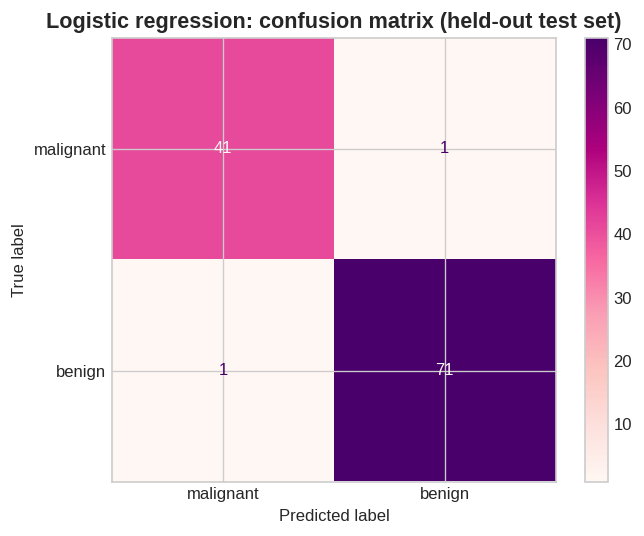

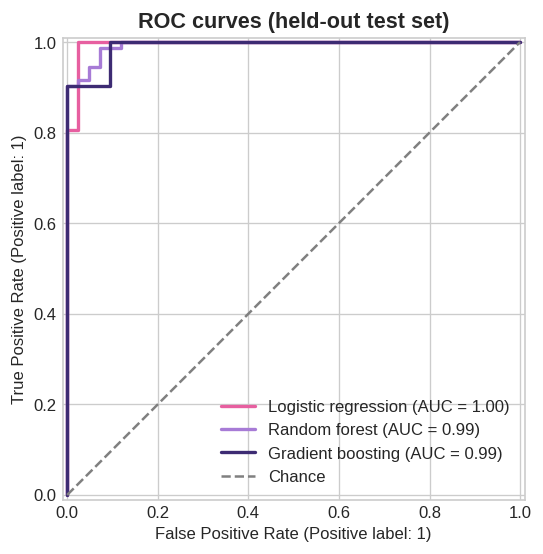

In [19]:
ConfusionMatrixDisplay.from_estimator(lr, X_test, y_test,
                                      display_labels=target_names, cmap='RdPu')
plt.title('Logistic regression: confusion matrix (held-out test set)')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
roc_colors = {'Logistic regression': '#e75fa0',   # hot pink
              'Random forest': '#a77bd6',         # medium purple
              'Gradient boosting': '#3d2b73'}     # deep indigo
for name, m in [('Logistic regression', lr), ('Random forest', rf), ('Gradient boosting', gb)]:
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax,
                                   color=roc_colors[name], linewidth=2)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Chance')
ax.legend()
plt.title('ROC curves (held-out test set)')
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## Where does the model make mistakes?
A confusion matrix shows which tumors the model got right and wrong. On the held-out test set (114 tumors), the logistic regression got 112 right. It missed 1 cancer and raised 1 false alarm.

The ROC curves compare the models across all possible cutoffs. All three are close to the top left, which means they separate the two classes well.

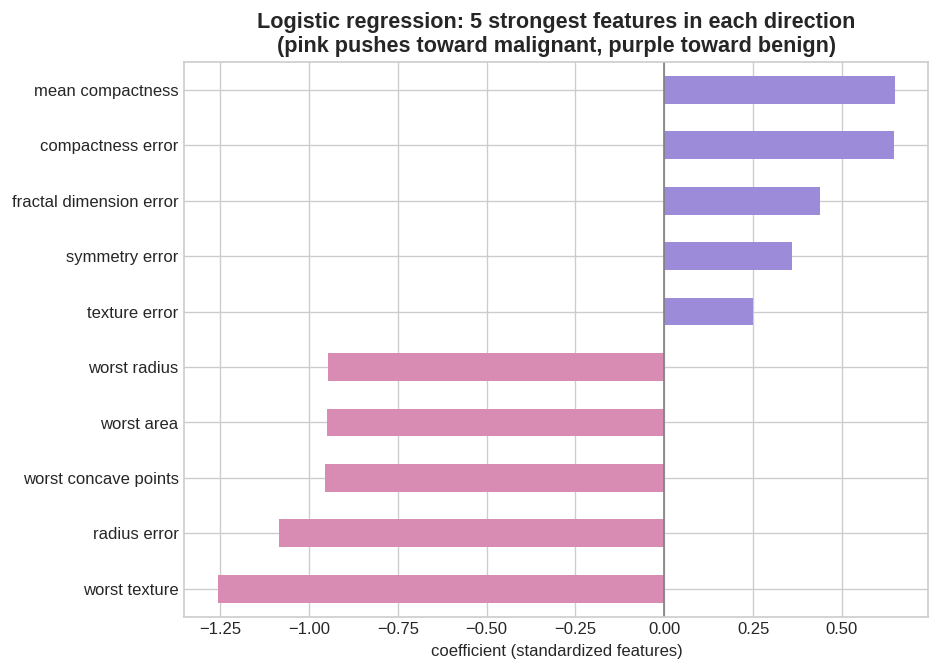

In [20]:
plot_top_coefficients(lr, X.columns, 'top_coefficients.png')

## Which measurements matter?
This chart shows the features the logistic regression weighted most in each direction. Pink pushes a prediction toward malignant and purple pushes it toward benign.

The feature names describe the size, shape, and texture of the cell nuclei. For example, "concave points" counts the dents in the outline of the nucleus, and "texture" describes how much the brightness varies. These are what the model weighted, not proof of what causes cancer, and many of the measurements overlap (radius, perimeter, and area are closely related).

## Extra experiments
**Lowering the cutoff:** I tested whether flagging tumors as malignant at lower probabilities would catch more cancers. It didn't. The one missed cancer stayed missed, while false alarms went from 1 to 11.

**Using fewer measurements:** With 20 of the 30 features, results were almost identical (97.5% accuracy). With only 3, accuracy dropped to 93.7% and malignant recall to 90.4%.

In [21]:
print('=== Lowering the "malignant" cutoff (logistic regression, test set) ===')
print(threshold_table(lr, X_test, y_test, [0.5, 0.4, 0.3, 0.2, 0.1]).to_string(index=False))

print('\n=== Using fewer features (logistic regression, cross-validated) ===')
print(feature_count_experiment(X, y, [3, 5, 10, 20, 30]).to_string(index=False))

=== Lowering the "malignant" cutoff (logistic regression, test set) ===
 cutoff  cancers caught  cancers missed  false alarms  malignant recall %
    0.5              41               1             1                97.6
    0.4              41               1             4                97.6
    0.3              41               1             5                97.6
    0.2              41               1             6                97.6
    0.1              41               1            11                97.6

=== Using fewer features (logistic regression, cross-validated) ===
 features used  accuracy %  malignant recall %
             3       93.73               90.42
             5       94.32               91.51
            10       95.14               92.61
            20       97.54               95.12
            30       97.60               95.12


## What did the model get wrong?
The missed cancer had mixed signals. Its texture and radius error looked benign, while its concavity and perimeter fell between the benign and malignant averages. The model gave it a 9% chance of being malignant, below even my lowest cutoff of 10%.

The false alarm was a benign tumor with high texture and concavity values, and the model was unsure about it (63% malignant).

With only two errors in 114 samples, I can't conclude much about why they happened. They look like borderline cases.

In [22]:
pred = lr.predict(X_test)
mask = pred != y_test.values
cols = ['worst texture', 'radius error', 'worst concave points',
        'worst concavity', 'worst perimeter', 'worst smoothness']

wrong = X_test[mask][cols].copy()
wrong['true class'] = y_test[mask].map({0: 'malignant', 1: 'benign'})
wrong['P(malignant)'] = lr.predict_proba(X_test)[mask, 0].round(3)
print('=== Misclassified test samples ===')
print(wrong.to_string())

labels = y.map({0: 'malignant', 1: 'benign'})
print('\n=== Average feature values by class (for comparison) ===')
print(X[cols].groupby(labels).mean().round(3).to_string())

=== Misclassified test samples ===
     worst texture  radius error  worst concave points  worst concavity  worst perimeter  worst smoothness true class  P(malignant)
541          31.73        0.2542                0.1205           0.4040            113.5            0.1340     benign         0.634
73           20.86        0.2787                0.1383           0.2779            110.3            0.1411  malignant         0.091

=== Average feature values by class (for comparison) ===
           worst texture  radius error  worst concave points  worst concavity  worst perimeter  worst smoothness
target                                                                                                          
benign            23.515         0.284                 0.074            0.166           87.006             0.125
malignant         29.318         0.609                 0.182            0.451          141.370             0.145


## Would more data help?
I plotted accuracy against the number of training samples to see whether performance is limited by the amount of data.

The cross-validated line flattens out, so adding more samples would probably not improve this model much.


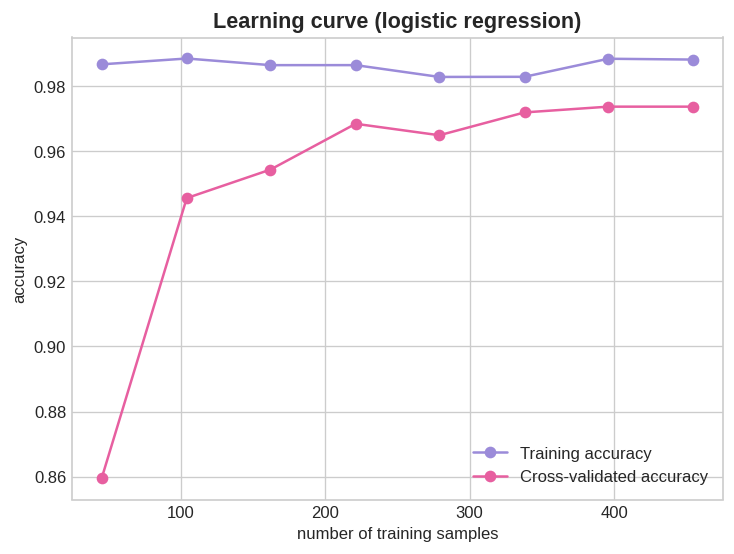

In [23]:
from sklearn.model_selection import learning_curve

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
sizes, train_scores, val_scores = learning_curve(
    models['Logistic regression'], X, y, cv=cv5,
    train_sizes=np.linspace(0.1, 1.0, 8), scoring='accuracy', n_jobs=-1)

plt.figure(figsize=(7, 5))
plt.plot(sizes, train_scores.mean(axis=1), 'o-', color='#9b8bd9', label='Training accuracy')
plt.plot(sizes, val_scores.mean(axis=1), 'o-', color='#e75fa0', label='Cross-validated accuracy')
plt.xlabel('number of training samples')
plt.ylabel('accuracy')
plt.title('Learning curve (logistic regression)')
plt.legend()
plt.savefig('learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()

## Explaining individual predictions
SHAP breaks one prediction into the contribution of each feature. I used it on one of the model's two mistakes on the test set: a benign tumor that it flagged as possibly malignant (63%). In the waterfall plot, red bars push toward malignant and blue bars push toward benign, and the longest bars are the features with the biggest effect. Here, worst texture was the biggest push toward malignant, and several features pulled the other way, but not enough.

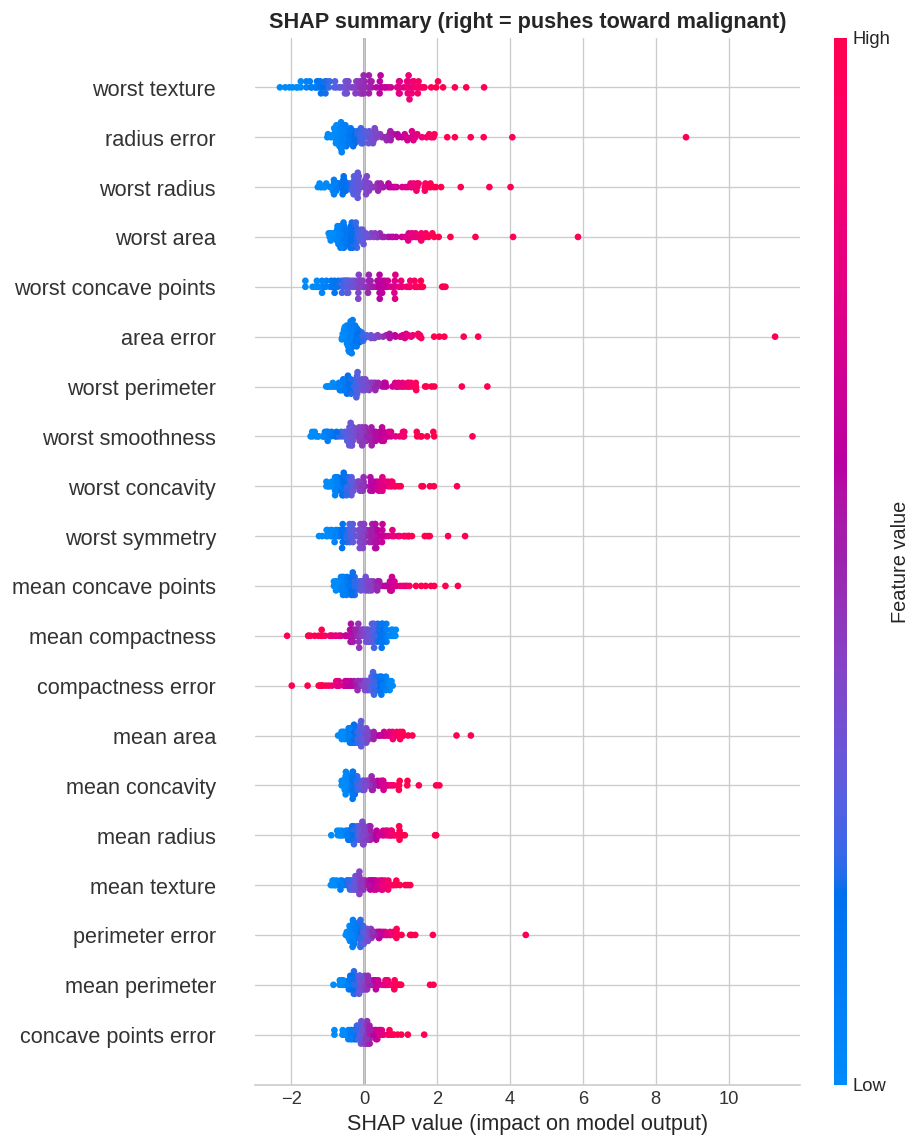

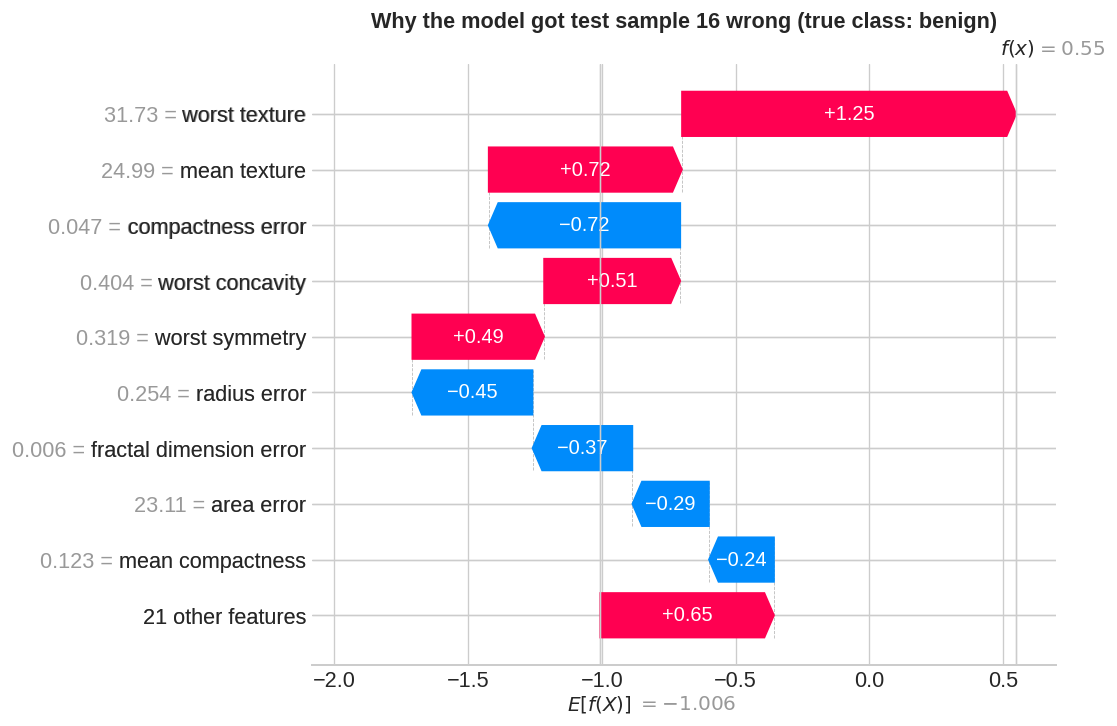

In [24]:
!pip install shap -q
import shap

scaler, clf = lr[0], lr[-1]
Xtr_s = scaler.transform(X_train)
Xte_s = scaler.transform(X_test)

explainer = shap.LinearExplainer(clf, Xtr_s)
sv = -explainer.shap_values(Xte_s)   # flipped: positive now means "toward malignant"
base = -explainer.expected_value

# 1) Overall picture
shap.summary_plot(sv, X_test, feature_names=list(X.columns), show=False)
plt.title('SHAP summary (right = pushes toward malignant)')
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# 2) Explain the tumor the model got wrong
wrong_idx = np.where(lr.predict(X_test) != y_test.values)[0]
i = int(wrong_idx[0])
exp = shap.Explanation(values=sv[i], base_values=base,
                       data=X_test.iloc[i].values, feature_names=list(X.columns))
shap.plots.waterfall(exp, show=False)
plt.title(f'Why the model got test sample {i} wrong (true class: '
          f'{target_names[int(y_test.iloc[i])]})')
plt.savefig('shap_missed_case.png', dpi=150, bbox_inches='tight')
plt.show()

## Conclusion and limitations
**What I found:** Logistic regression performed best, with about 97% cross-validated accuracy and about 94-95% malignant recall. Tuning didn't help, and about 20 measurements were enough.

**What I learned:** A simple model can beat more complex ones on a small, clean dataset, and accuracy alone isn't enough. What matters in medicine is which mistakes the model makes.

**Limitations:**
- Small, clean dataset from one source
- Even the best model missed about 1 in 20 cancers, which would not be acceptable in real use
- Only 114 test samples, so single errors move the numbers a lot
- Not a medical tool

**What I'd try next:** testing on a different dataset, and applying the same approach to a pharmaceutical based dataset!!